# Demonstração — testando os modelos com vinhos

Um "laboratório" para usar os modelos finais das Partes 1 e 2:

- **regressão** (`regression.ipynb`): prevê a nota (`quality`) como valor contínuo;
- **classificação** (`classification.ipynb`): prevê a faixa (baixa 3–4 / média 5–6 /
  alta 7–9) e a probabilidade de cada uma.

Nos dois casos, o modelo final foi o **Random Forest**. Este notebook não avalia nem
escolhe nada: os resultados oficiais estão nos notebooks das Partes 1 e 2. Aqui os
modelos são usados para classificar vinhos novos e para simular o efeito de cada
variável.

Roteiro: treino dos modelos finais → função de previsão → vinhos inventados →
vinhos reais do teste → simulações "e se?" → cuidados na interpretação.

## 1. Setup

In [1]:
import sys

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import root_mean_squared_error, f1_score

# Permite importar o módulo src/ a partir da pasta notebooks/
sys.path.append("..")
from src.preparacao import (RANDOM_STATE, COLUNAS_NUMERICAS, carregar_dados,
                            dividir_treino_teste, criar_pipeline)

# Cores dos gráficos
AZUL = "#2a78d6"
LARANJA = "#eb6834"
CINZA = "#898781"

# Esquema A da classificação: (0, 4] baixa, (4, 6] média, (6, 10] alta
LIMITES = [0, 4, 6, 10]
FAIXAS = ["baixa", "media", "alta"]


def criar_faixas(quality):
    """Converte as notas (quality) nas faixas do esquema A."""
    return pd.cut(quality, bins=LIMITES, labels=FAIXAS).astype(str)

## 2. Treino dos modelos finais

Os dois modelos são treinados de novo aqui, com **os melhores hiperparâmetros que o
`GridSearchCV` encontrou** nas Partes 1 e 2 (seção 6.2 da regressão e 7.2 da
classificação). Não é preciso repetir a busca: com o mesmo split, o mesmo
pré-processamento e a mesma semente, o modelo treinado é exatamente o mesmo.

A tabela abaixo confere isso: as métricas no teste devem bater com as dos notebooks
originais.

In [2]:
X, y = carregar_dados()
X_train, X_test, y_train, y_test = dividir_treino_teste(X, y)

faixa_train = criar_faixas(y_train)
faixa_test = criar_faixas(y_test)

# Melhores hiperparâmetros da regressão (seção 6.2 de regression.ipynb)
modelo_reg = criar_pipeline(RandomForestRegressor(
    n_estimators=500, max_depth=None, min_samples_leaf=1,
    random_state=RANDOM_STATE, n_jobs=-1,
)).fit(X_train, y_train)

# Melhores hiperparâmetros da classificação (seção 7.2 de classification.ipynb)
modelo_cls = criar_pipeline(RandomForestClassifier(
    n_estimators=500, max_depth=None, min_samples_leaf=3, class_weight="balanced",
    random_state=RANDOM_STATE, n_jobs=-1,
)).fit(X_train, faixa_train)

pd.DataFrame({
    "neste notebook": [
        root_mean_squared_error(y_test, modelo_reg.predict(X_test)),
        f1_score(faixa_test, modelo_cls.predict(X_test), average="macro"),
    ],
    "notebook original": [0.679, 0.603],
}, index=["RMSE (regressão)", "F1 macro (classificação)"]).round(3)

,neste notebook,notebook original
RMSE (regressão),0.679,0.679
F1 macro (classificação),0.603,0.603


## 3. Função de previsão

`prever` recebe uma tabela de vinhos (uma linha por vinho, com as 12 colunas do
dataset) e devolve, para cada um:

- **nota prevista**: saída da regressão (um número contínuo, como 6,4);
- **faixa prevista**: saída da classificação;
- **% de cada faixa**: a probabilidade que o modelo dá a cada faixa. No Random
  Forest, é a fração das 500 árvores que votou em cada faixa.

O pipeline faz todo o pré-processamento sozinho (mediana nos vazios, codificação do
`type`, padronização), do mesmo jeito que no treino. Por isso o vinho entra com os
valores originais, sem nenhum tratamento.

In [3]:
def prever(vinhos):
    """Nota prevista (regressão), faixa prevista e % de cada faixa (classificação)."""
    probabilidades = pd.DataFrame(
        modelo_cls.predict_proba(vinhos), columns=modelo_cls.classes_, index=vinhos.index,
    )
    resultado = pd.DataFrame({
        "nota prevista": modelo_reg.predict(vinhos),
        "faixa prevista": modelo_cls.predict(vinhos),
    }, index=vinhos.index)
    return resultado.join((100 * probabilidades[FAIXAS]).add_prefix("% "))

## 4. Vinhos inventados

### 4.1 Vinho típico

Ponto de partida para os testes: um vinho com **a mediana de cada variável** entre os
vinhos do mesmo tipo no treino. Tintos e brancos têm químicas bem diferentes (os
brancos têm muito mais açúcar e SO₂, por exemplo), por isso há um típico de cada
tipo.

In [4]:
def vinho_tipico(tipo):
    """Vinho com a mediana de cada variável entre os vinhos do tipo ("red" ou "white") no treino."""
    medianas = X_train.loc[X_train["type"] == tipo, COLUNAS_NUMERICAS].median()
    return pd.DataFrame([{**medianas, "type": tipo}])[X.columns]


tipicos = pd.concat([vinho_tipico("red"), vinho_tipico("white")])
tipicos.index = ["tinto típico", "branco típico"]

tipicos

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,type
tinto típico,8.0,0.51,0.26,2.2,0.079,14.0,38.0,0.99672,3.31,0.62,10.2,red
branco típico,6.8,0.26,0.32,4.7,0.042,33.0,133.0,0.99350,3.18,0.48,10.5,white


In [5]:
prever(tipicos).round(1)

,nota prevista,faixa prevista,% baixa,% media,% alta
tinto típico,5.9,media,5.2,84.6,10.2
branco típico,5.9,media,4.8,66.2,29.0


**Observações:**

- **Os dois vinhos típicos recebem nota 5,9 e faixa "média".** Faz sentido: com a
  mediana de cada variável, eles são vinhos "do meio", e as notas mais comuns são 5
  e 6.
- **A diferença está nas probabilidades:** o branco típico tem 29% de chance de ser
  "alta", contra 10% do tinto. No treino, 21% dos brancos têm nota 7 ou mais, contra
  14% dos tintos. A chance de "baixa" é parecida nos dois (cerca de 5%), como no
  treino.

### 4.2 Seu vinho

Altere os valores abaixo e rode a célula para testar outro vinho. O exemplo é um
branco com álcool alto e acidez volátil baixa, as duas características que mais
puxam a nota para cima (seção 8 da regressão).

Para o resultado fazer sentido, use valores **dentro da faixa vista no treino** (a
tabela da célula seguinte mostra o mínimo e o máximo de cada variável). Fora dela, o
modelo não tem exemplos para se basear.

In [6]:
meu_vinho = pd.DataFrame([{
    "fixed acidity": 6.8,
    "volatile acidity": 0.20,
    "citric acid": 0.32,
    "residual sugar": 3.0,
    "chlorides": 0.035,
    "free sulfur dioxide": 40,
    "total sulfur dioxide": 120,
    "density": 0.991,
    "pH": 3.2,
    "sulphates": 0.50,
    "alcohol": 12.5,
    "type": "white",   # "red" ou "white"
}], index=["meu vinho"])

prever(meu_vinho).round(1)

,nota prevista,faixa prevista,% baixa,% media,% alta
meu vinho,6.7,alta,0.1,19.2,80.7


In [7]:
# Faixa de valores de cada variável no treino, por tipo
X_train.groupby("type")[COLUNAS_NUMERICAS].agg(["min", "median", "max"]).T.round(3)

type                             red    white
fixed acidity        min       4.600    3.800
                     median    8.000    6.800
                     max      15.900   14.200
volatile acidity     min       0.120    0.080
                     median    0.510    0.260
                     max       1.580    1.100
citric acid          min       0.000    0.000
                     median    0.260    0.320
                     max       0.790    1.660
residual sugar       min       0.900    0.600
                     median    2.200    4.700
                     max      15.500   65.800
chlorides            min       0.012    0.009
                     median    0.079    0.042
                     max       0.611    0.346
free sulfur dioxide  min       1.000    2.000
                     median   14.000   33.000
                     max      68.000  289.000
total sulfur dioxide min       7.000    9.000
                     median   38.000  133.000
                     max     289.000  440.000
density              min       0.990    0.987
                     median    0.997    0.994
                     max       1.004    1.039
pH                   min       2.860    2.720
                     median    3.310    3.180
                     max       4.010    3.820
sulphates            min       0.330    0.220
                     median    0.620    0.480
                     max       1.980    1.080
alcohol              min       8.400    8.000
                     median   10.200   10.500
                     max      14.900   14.200

**Observações:**

- **O vinho do exemplo sai como "alta", com 81% de probabilidade**, e nota prevista
  de 6,7. Em relação ao branco típico (nota 5,9 e 29% de "alta"), as maiores
  mudanças são o álcool (10,5 → 12,5) e a acidez volátil (0,26 → 0,20).
- As faixas de valores são bem diferentes entre os tipos: os brancos chegam a
  65,8 g/L de açúcar e 289 mg/L de SO₂ livre; os tintos, a 15,5 e 68. Um valor normal
  para um tipo pode ser extremo para o outro.

## 5. Vinhos reais do teste

Um vinho sorteado de **cada nota** do conjunto de teste, com a nota e a faixa reais
ao lado das previstas. As três primeiras colunas mostram as variáveis mais
importantes de cada vinho.

In [8]:
# Um vinho sorteado de cada nota (a nota 9 tem um vinho só no teste)
amostra = X_test.groupby(y_test).sample(1, random_state=RANDOM_STATE)

exemplos = amostra[["type", "alcohol", "volatile acidity", "free sulfur dioxide"]].join(prever(amostra))
exemplos.insert(4, "nota real", y_test[amostra.index])
exemplos.insert(5, "faixa real", faixa_test[amostra.index])

exemplos.round(2)

,type,alcohol,volatile acidity,free sulfur dioxide,nota real,faixa real,nota prevista,faixa prevista,% baixa,% media,% alta
2609,white,9.1,0.32,8.0,3,baixa,4.95,media,47.81,48.56,3.63
2659,white,9.1,0.53,29.0,4,baixa,5.17,baixa,50.13,41.04,8.82
3691,white,9.4,0.45,31.0,5,media,5.29,media,13.82,83.99,2.19
1924,white,9.1,0.28,44.0,6,media,5.14,media,12.85,84.38,2.77
2293,white,11.5,0.32,25.0,7,alta,6.64,alta,7.68,31.06,61.25
2595,white,12.7,0.44,46.0,8,alta,7.33,alta,3.40,15.90,80.70
2012,white,10.4,0.27,28.0,9,alta,5.63,media,24.60,54.34,21.07


**Observações:**

- Os sete sorteados são brancos por acaso: 75% dos vinhos do teste são brancos.
- **A faixa foi acertada em 5 dos 7 vinhos.** Os dois erros:
  - **nota 3 → "média"**, mas quase empatado: 48,6% "média" contra 47,8% "baixa".
  - **nota 9 → "média"** (nota prevista 5,6). É o único vinho 9 do teste, e há só 4 no
    treino. Além disso, a química dele é comum (álcool 10,4, acidez volátil 0,27):
    pelas variáveis, ele parece um vinho médio.
- **A regressão puxa as notas para o centro**, como na seção 7.1 da Parte 1: a nota 3
  vira 4,95, a nota 8 vira 7,33 e a nota 9 vira 5,63.
- **As probabilidades mostram a confiança do modelo**: 84% de "média" nos vinhos 5 e
  6, 81% de "alta" no vinho 8 (álcool 12,7), e quase empate no vinho 3.

## 6. Simulações "e se?"

Pegamos o vinho típico e mudamos **uma variável de cada vez**, mantendo as outras
fixas, para ver como as previsões respondem. As três variáveis são as mais
importantes nas Partes 1 e 2: `alcohol`, `volatile acidity` e `free sulfur dioxide`.

Cada variável vai do percentil 1 ao 99 dos vinhos do mesmo tipo no treino: uma faixa
de valores realista para tintos e para brancos.

- **Linha de cima:** nota prevista (regressão).
- **Linha de baixo:** probabilidade das faixas alta e baixa (classificação). A da
  faixa média é o que falta para 100%.
- **Linha cheia** = branco típico; **tracejada** = tinto típico.

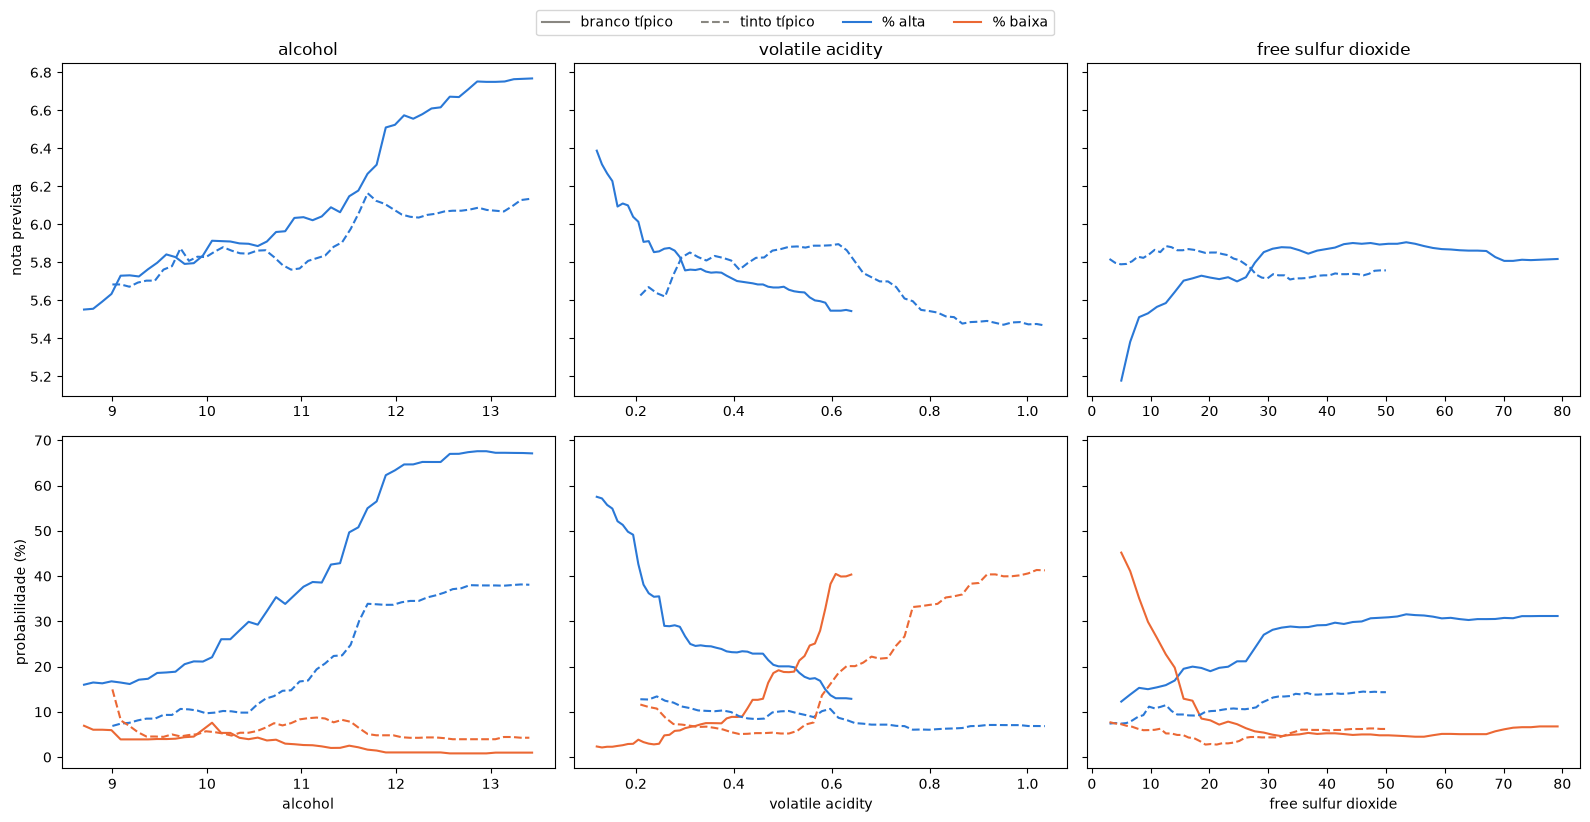

In [9]:
def variar(vinho, coluna, valores):
    """Repete o vinho mudando só uma coluna e devolve as previsões para cada valor."""
    vinhos = pd.concat([vinho] * len(valores), ignore_index=True)
    vinhos[coluna] = valores
    return prever(vinhos).set_index(pd.Index(valores, name=coluna))


VARIAVEIS = ["alcohol", "volatile acidity", "free sulfur dioxide"]
TIPOS = {"white": "-", "red": "--"}   # estilo da linha de cada tipo

simulacoes = {}
for coluna in VARIAVEIS:
    for tipo in TIPOS:
        do_tipo = X_train.loc[X_train["type"] == tipo, coluna]
        valores = np.linspace(do_tipo.quantile(0.01), do_tipo.quantile(0.99), 50)
        simulacoes[(coluna, tipo)] = variar(vinho_tipico(tipo), coluna, valores)

fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey="row")

for j, coluna in enumerate(VARIAVEIS):
    for tipo, estilo in TIPOS.items():
        curva = simulacoes[(coluna, tipo)]
        axes[0, j].plot(curva.index, curva["nota prevista"], estilo, color=AZUL)
        axes[1, j].plot(curva.index, curva["% alta"], estilo, color=AZUL)
        axes[1, j].plot(curva.index, curva["% baixa"], estilo, color=LARANJA)
    axes[0, j].set_title(coluna)
    axes[1, j].set_xlabel(coluna)

axes[0, 0].set_ylabel("nota prevista")
axes[1, 0].set_ylabel("probabilidade (%)")

# Legenda: estilo da linha = tipo; cor (linha de baixo) = faixa
fig.legend(handles=[
    Line2D([], [], color=CINZA, linestyle="-", label="branco típico"),
    Line2D([], [], color=CINZA, linestyle="--", label="tinto típico"),
    Line2D([], [], color=AZUL, label="% alta"),
    Line2D([], [], color=LARANJA, label="% baixa"),
], loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.03))

plt.tight_layout()
plt.show()

In [10]:
# Os números por trás dos gráficos: previsões no início e no fim de cada faixa de valores
pd.DataFrame({
    (coluna, {"white": "branco", "red": "tinto"}[tipo]): {
        "valor inicial": curva.index[0],
        "valor final": curva.index[-1],
        "nota inicial": curva["nota prevista"].iloc[0],
        "nota final": curva["nota prevista"].iloc[-1],
        "% alta inicial": curva["% alta"].iloc[0],
        "% alta final": curva["% alta"].iloc[-1],
        "% baixa inicial": curva["% baixa"].iloc[0],
        "% baixa final": curva["% baixa"].iloc[-1],
    }
    for (coluna, tipo), curva in simulacoes.items()
}).round(2)

alcohol        volatile acidity        free sulfur dioxide  \
                 branco  tinto           branco  tinto              branco   
valor inicial      8.70   9.00             0.12   0.21                5.00   
valor final       13.44  13.41             0.64   1.04               79.19   
nota inicial       5.55   5.68             6.39   5.63                5.18   
nota final         6.77   6.13             5.54   5.47                5.82   
% alta inicial    15.99   6.88            57.51  12.78               12.27   
% alta final      67.10  38.08            12.88   6.85               31.17   
% baixa inicial    6.92  14.96             2.34  11.61               45.18   
% baixa final      0.99   4.28            40.33  41.26                6.78   

                        
                 tinto  
valor inicial     3.00  
valor final      50.00  
nota inicial      5.82  
nota final        5.76  
% alta inicial    7.40  
% alta final     14.34  
% baixa inicial   7.72  
% baixa final     6.21

**Observações:**

- **O álcool é a variável com maior efeito.** No branco típico, de 8,7% a 13,4%, a
  nota prevista vai de 5,55 a 6,77 e a chance de "alta", de 16% a 67%. A maior subida
  acontece entre 11,5% e 12%. No tinto, o efeito é menor: nota de 5,68 a 6,13 e
  chance de "alta" de 7% a 38%.
- **A acidez volátil tem o efeito contrário.** No branco, de 0,12 a 0,64, a nota cai de
  6,39 para 5,54 e a chance de "baixa" sobe de 2% para 40%. No tinto, a chance de
  "baixa" sobe a partir de 0,6 e chega a 41%. Entre 0,2 e 0,6, a nota prevista do
  tinto sobe um pouco antes de cair. Só 87 tintos do treino (8%) têm acidez volátil
  abaixo de 0,3, então o modelo tem poucos exemplos dessa região.
- **O SO₂ livre importa sobretudo nos brancos, e só quando é baixo.** Abaixo de cerca
  de 15 mg/L, a chance de "baixa" do branco sobe até 45%; acima de 30, a curva fica
  plana. No tinto, a curva é quase plana em toda a faixa.
- **As curvas têm "degraus" e ficam planas nas pontas.** O Random Forest é feito de
  árvores, que dividem cada variável em intervalos: dentro de um intervalo, a
  previsão não muda. Pelo mesmo motivo, o modelo não extrapola: acima do maior
  álcool visto no treino, a previsão continua igual à do último intervalo.

## 7. Cuidados na interpretação

As simulações mostram **o que o modelo aprendeu**, não como fazer um vinho melhor.

1. **Associação não é causa.** O gráfico mostra que vinhos com mais álcool tendem a
   receber notas maiores, não que acrescentar álcool melhora um vinho. O álcool
   pode estar "carregando" outros fatores que não estão nos dados, como uvas mais
   maduras ou uma fermentação mais completa.
2. **As variáveis não mudam sozinhas.** Mudar uma variável e manter as outras fixas
   pode criar vinhos que não existem. O álcool e a densidade, por exemplo, têm
   correlação de −0,66 no treino: um vinho com 14% de álcool e densidade típica é
   quimicamente improvável.
3. **Fora da faixa do treino, a previsão não é confiável.** O modelo não tem exemplos
   para se basear e só repete a previsão do valor mais próximo que conhece.
4. **Probabilidade não é certeza.** "60% de alta" significa que 60% das árvores
   votaram em "alta". No teste, o modelo erra a faixa de cerca de 1 em cada 4
   vinhos (acurácia de 0,75).

## 8. Conclusões

1. **Os modelos treinados aqui são idênticos aos das Partes 1 e 2**: as métricas no
   teste batem com as dos notebooks originais (RMSE de 0,679 e F1 macro de 0,603).
2. **A função `prever` classifica qualquer vinho** a partir dos valores originais
   das 12 variáveis, com a nota prevista, a faixa e a probabilidade de cada faixa.
3. **Nos vinhos reais**, o modelo acerta a faixa da maioria e mostra pouca confiança
   onde erra (quase empate no vinho 3). Os vinhos extremos continuam sendo os mais
   difíceis, principalmente os de química comum, como o vinho 9 sorteado.
4. **As simulações confirmam a importância das variáveis** vista nas Partes 1 e 2:
   mais álcool aumenta a chance de "alta"; mais acidez volátil e pouco SO₂ livre (nos
   brancos) aumentam a chance de "baixa".
5. **Os efeitos são diferentes entre tintos e brancos**: o álcool pesa mais nos
   brancos, e o SO₂ livre quase só importa neles. É o mesmo resultado da análise
   exploratória, que justificou manter o `type` como variável dos modelos.